In [1]:
import sys
import pandas as pd
import statsmodels.api as sm

print(sys.executable)
print(pd.__version__)

/Users/ElijahSong/Documents/Election26/.venv/bin/python
3.1.0


In [2]:
"""
Input Schema 1:
===============
data/raw/fivethirtyeight.data.congress-generic-ballot/generic_ballot_averages.csv
* 2017-04-15 (2018) to 2024-11-05 (2024)

        candidate, pct_estimate, lo, hi, date, election?, cycle
i       D
i + 1   R

NOTE: Be careful of two-row format. election? means election field can be empty.

--> Intermediate Schema:
modeldate, dem_estimate, dem_hi, dem_lo, rep_estimate, rep_hi, rep_lo, timestamp

LEAVE timestamp empty


Input Schema 2:
===============
data/raw/fivethirtyeight.data.congress-generic-ballot/generic_topline_historical.csv
* 11/9/95 (1996) to 11/6/2016 (2016)

modeldate, dem_estimate, dem_hi, dem_lo, rep_estimate, rep_hi, rep_lo, timestamp

NOTE: modeldate is a string, not in Date or DateTime format


Output Schema:
===============
election, date, margin_raw, margin_2p_norm, dem_estimate, gop_estimate, und_estimate, dem_hi, dem_lo, gop_hi, gop_lo 

where Date is in a Date/DateTime format
"""

'\nInput Schema 1:\n===============\ndata/raw/fivethirtyeight.data.congress-generic-ballot/generic_ballot_averages.csv\n* 2017-04-15 (2018) to 2024-11-05 (2024)\n\n        candidate, pct_estimate, lo, hi, date, election?, cycle\ni       D\ni + 1   R\n\nNOTE: Be careful of two-row format. election? means election field can be empty.\n\n--> Intermediate Schema:\nmodeldate, dem_estimate, dem_hi, dem_lo, rep_estimate, rep_hi, rep_lo, timestamp\n\nLEAVE timestamp empty\n\n\nInput Schema 2:\n===============\ndata/raw/fivethirtyeight.data.congress-generic-ballot/generic_topline_historical.csv\n* 11/9/95 (1996) to 11/6/2016 (2016)\n\nmodeldate, dem_estimate, dem_hi, dem_lo, rep_estimate, rep_hi, rep_lo, timestamp\n\nNOTE: modeldate is a string, not in Date or DateTime format\n\n\nOutput Schema:\n===============\nelection, date, margin_raw, margin_2p_norm, dem_estimate, gop_estimate, und_estimate, dem_hi, dem_lo, gop_hi, gop_lo \n\nwhere Date is in a Date/DateTime format\n'

In [3]:
from pathlib import Path

DATA_DIR = Path("../../data/raw/fivethirtyeight.data.congress-generic-ballot")
TOPLINE_COLUMNS = ["modeldate", "dem_estimate", "dem_hi", "dem_lo", "rep_estimate", "rep_hi", "rep_lo", "timestamp"]


def load_topline_historical(path: Path = DATA_DIR / "generic_topline_historical.csv") -> pd.DataFrame:
    """Load the historical generic-ballot topline in the topline schema, with modeldate parsed to a date."""
    df = pd.read_csv(path)
    df["modeldate"] = pd.to_datetime(df["modeldate"], format="%m/%d/%y")
    return df[TOPLINE_COLUMNS].sort_values("modeldate", ignore_index=True)


load_topline_historical()["modeldate"].max()

Timestamp('2016-11-06 00:00:00')

In [4]:
PARTY_PREFIX = {"Democrats": "dem", "Republicans": "rep"}


def averages_to_topline(path: Path = DATA_DIR / "generic_ballot_averages.csv") -> pd.DataFrame:
    """Reshape the two-row-per-date (D, R) averages file into the one-row-per-date topline schema."""
    df = pd.read_csv(path, parse_dates=["date"])
    df["party"] = df["candidate"].map(PARTY_PREFIX)
    if df["party"].isna().any():
        raise ValueError(f"Unexpected candidates: {df.loc[df['party'].isna(), 'candidate'].unique()}")

    # pivot raises if any (date, party) pair appears more than once, so a broken D/R pairing fails loudly
    wide = df.rename(columns={"pct_estimate": "estimate"}).pivot(
        index="date", columns="party", values=["estimate", "hi", "lo"]
    )
    wide.columns = [f"{party}_{stat}" for stat, party in wide.columns]

    out = wide.reset_index().rename(columns={"date": "modeldate"})
    out["timestamp"] = pd.NA
    return out[TOPLINE_COLUMNS].sort_values("modeldate", ignore_index=True)


averages_topline = averages_to_topline()
averages_topline

,modeldate,dem_estimate,dem_hi,dem_lo,rep_estimate,rep_hi,rep_lo,timestamp
0,2017-04-15,43.944490,48.555500,39.333470,39.549690,44.160710,34.938670,<NA>
1,2017-04-16,43.749650,48.358760,39.140540,39.592540,44.201650,34.983430,<NA>
2,2017-04-17,43.745530,48.355080,39.135990,39.587940,44.197490,34.978400,<NA>
3,2017-04-18,43.740520,48.350620,39.130420,39.582230,44.192330,34.972130,<NA>
4,2017-04-19,43.410340,47.980300,38.840390,38.840260,43.410220,34.270310,<NA>
...,...,...,...,...,...,...,...,...
2320,2024-11-01,46.158931,48.565366,43.752496,45.612154,47.673923,43.550385,<NA>
2321,2024-11-02,46.105173,48.494495,43.715851,45.621481,47.678494,43.564468,<NA>
2322,2024-11-03,46.284085,48.672300,43.895870,45.705679,47.795748,43.615610,<NA>
2323,2024-11-04,46.313940,48.695299,43.932581,45.635860,47.715078,43.556642,<NA>


In [5]:
import json

REFERENCE_DIR = Path("../../data/reference")


def load_election_dates(path: Path = REFERENCE_DIR / "election_dates.json") -> pd.DataFrame:
    """Load election days as a sorted (election, election_day, day_before) frame, where election is the cycle year."""
    with open(path) as f:
        raw = json.load(f)
    dates = pd.DataFrame(
        {"election": int(year), "election_day": pd.Timestamp(d["election_day"]), "day_before": pd.Timestamp(d["day_before"])}
        for year, d in raw.items()
    )
    return dates.sort_values("election_day", ignore_index=True)


def add_election(df: pd.DataFrame, election_dates: pd.DataFrame) -> pd.DataFrame:
    """Insert a leading `election` column: the year of the first election_day on or after modeldate."""
    df = df.sort_values("modeldate", ignore_index=True)
    matched = pd.merge_asof(
        df[["modeldate"]],
        election_dates.astype({"election_day": df["modeldate"].dtype}),
        left_on="modeldate",
        right_on="election_day",
        direction="forward",
    )
    if matched["election"].isna().any():
        raise ValueError(f"modeldate after last known election day: {df.loc[matched['election'].isna(), 'modeldate'].max()}")

    out = df.copy()
    out.insert(0, "election", matched["election"].astype(int))
    return out


election_dates = load_election_dates()
averages_topline = add_election(averages_topline, election_dates)
averages_topline

,election,modeldate,dem_estimate,dem_hi,dem_lo,rep_estimate,rep_hi,rep_lo,timestamp
0,2018,2017-04-15,43.944490,48.555500,39.333470,39.549690,44.160710,34.938670,<NA>
1,2018,2017-04-16,43.749650,48.358760,39.140540,39.592540,44.201650,34.983430,<NA>
2,2018,2017-04-17,43.745530,48.355080,39.135990,39.587940,44.197490,34.978400,<NA>
3,2018,2017-04-18,43.740520,48.350620,39.130420,39.582230,44.192330,34.972130,<NA>
4,2018,2017-04-19,43.410340,47.980300,38.840390,38.840260,43.410220,34.270310,<NA>
...,...,...,...,...,...,...,...,...,...
2320,2024,2024-11-01,46.158931,48.565366,43.752496,45.612154,47.673923,43.550385,<NA>
2321,2024,2024-11-02,46.105173,48.494495,43.715851,45.621481,47.678494,43.564468,<NA>
2322,2024,2024-11-03,46.284085,48.672300,43.895870,45.705679,47.795748,43.615610,<NA>
2323,2024,2024-11-04,46.313940,48.695299,43.932581,45.635860,47.715078,43.556642,<NA>


In [6]:
historical_topline = add_election(load_topline_historical(), election_dates)
historical_topline

,election,modeldate,dem_estimate,dem_hi,dem_lo,rep_estimate,rep_hi,rep_lo,timestamp
0,1996,1995-11-09,50.00000,56.30568,43.69432,44.00000,50.30568,37.69432,9/3/20 11:37
1,1996,1995-11-10,50.00000,56.30568,43.69432,44.00000,50.30568,37.69432,9/3/20 11:37
2,1996,1995-11-11,50.00000,56.30568,43.69432,44.00000,50.30568,37.69432,9/3/20 11:37
3,1996,1995-11-12,50.00000,56.30568,43.69432,44.00000,50.30568,37.69432,9/3/20 11:37
4,1996,1995-11-13,50.00000,56.30568,43.69432,44.00000,50.30568,37.69432,9/3/20 11:37
...,...,...,...,...,...,...,...,...,...
7664,2016,2016-11-02,44.75213,50.02578,39.47849,41.80472,46.49487,37.11458,9/2/20 17:17
7665,2016,2016-11-03,44.67450,49.95118,39.39781,41.86721,46.53036,37.20405,9/2/20 17:16
7666,2016,2016-11-04,44.94021,50.15437,39.72605,42.43640,47.29121,37.58159,9/2/20 17:16
7667,2016,2016-11-05,44.94520,50.14077,39.74964,42.36770,47.22380,37.51159,9/2/20 17:15


In [7]:
INTERIM_COLUMNS = [
    "election", "date", "margin_raw", "margin_2p_norm",
    "dem_estimate", "gop_estimate", "und_estimate", "dem_hi", "dem_lo", "gop_hi", "gop_lo",
]
INTERIM_RENAMES = {
    "modeldate": "date",
    "rep_estimate": "gop_estimate",
    "rep_hi": "gop_hi",
    "rep_lo": "gop_lo",
}


def add_margins(df: pd.DataFrame) -> pd.DataFrame:
    """Add the D-R margin, the margin as a share of the two-party total, and the undecided share."""
    out = df.copy()
    two_party = out["dem_estimate"] + out["gop_estimate"]
    out["margin_raw"] = out["dem_estimate"] - out["gop_estimate"]
    # a zero or missing two-party total has no defined share, so it becomes NaN instead of inf
    out["margin_2p_norm"] = 100 * out["margin_raw"] / two_party.where(two_party > 0)
    out["und_estimate"] = 100 - two_party
    return out


def to_interim(topline: pd.DataFrame) -> pd.DataFrame:
    """Convert a topline frame (with election) into the interim generic-ballot schema."""
    return add_margins(topline.rename(columns=INTERIM_RENAMES))[INTERIM_COLUMNS]

In [ ]:
TREND_WINDOW_DAYS = 30
TREND_MARGINS = {"raw": "margin_raw", "2p_norm": "margin_2p_norm"}


def add_trend_features(df: pd.DataFrame, window: int = TREND_WINDOW_DAYS) -> pd.DataFrame:
    """Add per-cycle rolling mean, EWMA and momentum (M_t - M_{t-window days}) for each margin.

    Rows without a full `window` days of history in their cycle are left NaN, so every non-NaN value
    is computed from the same amount of data.
    """
    out = df.sort_values("date", ignore_index=True)
    by_cycle = out.groupby("election")
    gaps = by_cycle["date"].diff().dropna()
    if (gaps != pd.Timedelta(days=1)).any():
        raise ValueError("Trend features assume one row per day within each cycle")

    has_history = by_cycle["date"].shift(window).notna()
    for suffix, col in TREND_MARGINS.items():
        margin = by_cycle[col]
        features = {
            f"margin_{window}d_mean_{suffix}": margin.transform(lambda m: m.rolling(window).mean()),
            f"margin_{window}d_ewma_{suffix}": margin.transform(lambda m: m.ewm(span=window).mean()),
            f"momentum_{window}d_{suffix}": out[col] - margin.shift(window),
        }
        for name, values in features.items():
            out[name] = values.where(has_history)
    return out

In [8]:
INTERIM_DIR = Path("../../data/interim")

generic_ballot = to_interim(pd.concat([historical_topline, averages_topline], ignore_index=True)).sort_values(
    "date", ignore_index=True
)
if generic_ballot["date"].duplicated().any():
    raise ValueError("Historical and averages sources overlap on date")
if (generic_ballot["und_estimate"] < 0).any():
    raise ValueError("dem_estimate + rep_estimate exceeds 100 on some dates")

generic_ballot = add_trend_features(generic_ballot)

generic_ballot.to_parquet(INTERIM_DIR / "generic_ballot_all.parquet", index=False)
generic_ballot.to_csv(INTERIM_DIR / "generic_ballot_all.csv", index=False)
generic_ballot

,election,date,margin_raw,margin_2p_norm,dem_estimate,gop_estimate,und_estimate,dem_hi,dem_lo,gop_hi,gop_lo
0,1996,1995-11-09,6.000000,6.382979,50.000000,44.000000,6.000000,56.305680,43.694320,50.305680,37.694320
1,1996,1995-11-10,6.000000,6.382979,50.000000,44.000000,6.000000,56.305680,43.694320,50.305680,37.694320
2,1996,1995-11-11,6.000000,6.382979,50.000000,44.000000,6.000000,56.305680,43.694320,50.305680,37.694320
3,1996,1995-11-12,6.000000,6.382979,50.000000,44.000000,6.000000,56.305680,43.694320,50.305680,37.694320
4,1996,1995-11-13,6.000000,6.382979,50.000000,44.000000,6.000000,56.305680,43.694320,50.305680,37.694320
...,...,...,...,...,...,...,...,...,...,...,...
9989,2024,2024-11-01,0.546777,0.595805,46.158931,45.612154,8.228915,48.565366,43.752496,47.673923,43.550385
9990,2024,2024-11-02,0.483692,0.527319,46.105173,45.621481,8.273346,48.494495,43.715851,47.678494,43.564468
9991,2024,2024-11-03,0.578406,0.628772,46.284085,45.705679,8.010236,48.672300,43.895870,47.795748,43.615610
9992,2024,2024-11-04,0.678080,0.737446,46.313940,45.635860,8.050200,48.695299,43.932581,47.715078,43.556642


Now add a cell to visualize each
  election (e.g. given an election, graph all the
  `modeldate` and dem_estimate (blue line) and
  gop_estimate (red line)). The user would edit a constant
  ELECTION_YEAR and run a function. Make a second graph
  that incorporates the shaded "dem_hi, dem_lo" and
  "rep_hi, rep_lo" (blue low opacity and red low opacity)
  respectively. And a third graph with the margin.

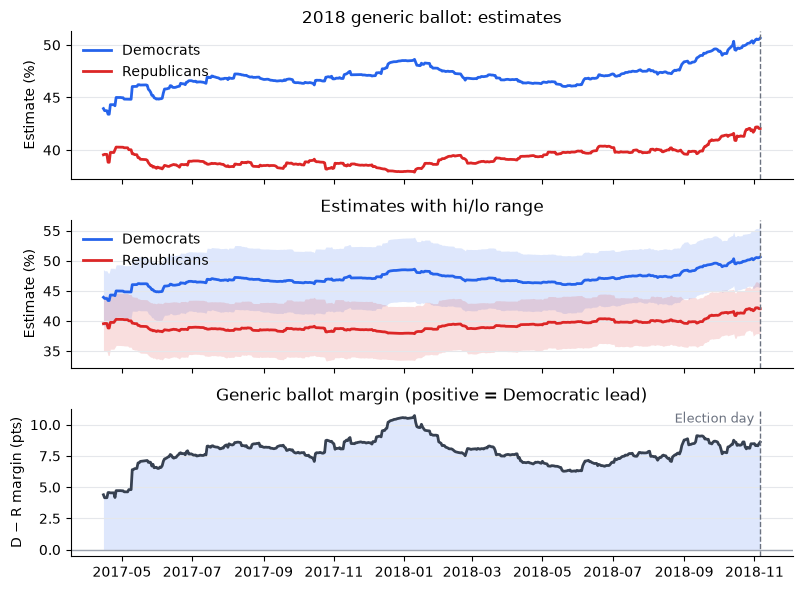

In [9]:
import matplotlib.pyplot as plt

ELECTION_YEAR = 2018

DEM_COLOR = "#2563eb"
GOP_COLOR = "#dc2626"
BAND_ALPHA = 0.15
FIGSIZE = (8, 6)


def plot_election(df: pd.DataFrame, election_year: int, election_dates: pd.DataFrame = election_dates) -> plt.Figure:
    """Plot one cycle: estimates, estimates with hi/lo bands, and the D-R margin, sharing one date axis."""
    cycle = df[df["election"] == election_year].sort_values("date")
    if cycle.empty:
        raise ValueError(f"No data for {election_year}; available: {sorted(df['election'].unique().tolist())}")
    election_day = election_dates.set_index("election").loc[election_year, "election_day"]

    fig, (ax_est, ax_band, ax_margin) = plt.subplots(3, 1, figsize=FIGSIZE, sharex=True)

    for ax in (ax_est, ax_band):
        ax.plot(cycle["date"], cycle["dem_estimate"], color=DEM_COLOR, lw=2, label="Democrats")
        ax.plot(cycle["date"], cycle["gop_estimate"], color=GOP_COLOR, lw=2, label="Republicans")
        ax.set_ylabel("Estimate (%)")
        ax.legend(loc="upper left", frameon=False)
    ax_band.fill_between(cycle["date"], cycle["dem_lo"], cycle["dem_hi"], color=DEM_COLOR, alpha=BAND_ALPHA, lw=0)
    ax_band.fill_between(cycle["date"], cycle["gop_lo"], cycle["gop_hi"], color=GOP_COLOR, alpha=BAND_ALPHA, lw=0)
    ax_est.set_title(f"{election_year} generic ballot: estimates")
    ax_band.set_title("Estimates with hi/lo range")

    margin = cycle["margin_raw"]
    ax_margin.plot(cycle["date"], margin, color="#374151", lw=2)
    ax_margin.fill_between(cycle["date"], margin, 0, where=margin >= 0, color=DEM_COLOR, alpha=BAND_ALPHA, lw=0, interpolate=True)
    ax_margin.fill_between(cycle["date"], margin, 0, where=margin < 0, color=GOP_COLOR, alpha=BAND_ALPHA, lw=0, interpolate=True)
    ax_margin.axhline(0, color="#9ca3af", lw=1)
    ax_margin.set_ylabel("D − R margin (pts)")
    ax_margin.set_title("Generic ballot margin (positive = Democratic lead)")

    for ax in (ax_est, ax_band, ax_margin):
        ax.axvline(election_day, color="#6b7280", lw=1, ls="--")
        ax.grid(axis="y", color="#e5e7eb", lw=0.8)
        ax.spines[["top", "right"]].set_visible(False)
    ax_margin.annotate("Election day", (election_day, 1), xycoords=("data", "axes fraction"),
                       ha="right", va="top", fontsize=9, color="#6b7280", xytext=(-4, -2), textcoords="offset points")

    fig.tight_layout()
    return fig


plot_election(generic_ballot, ELECTION_YEAR);

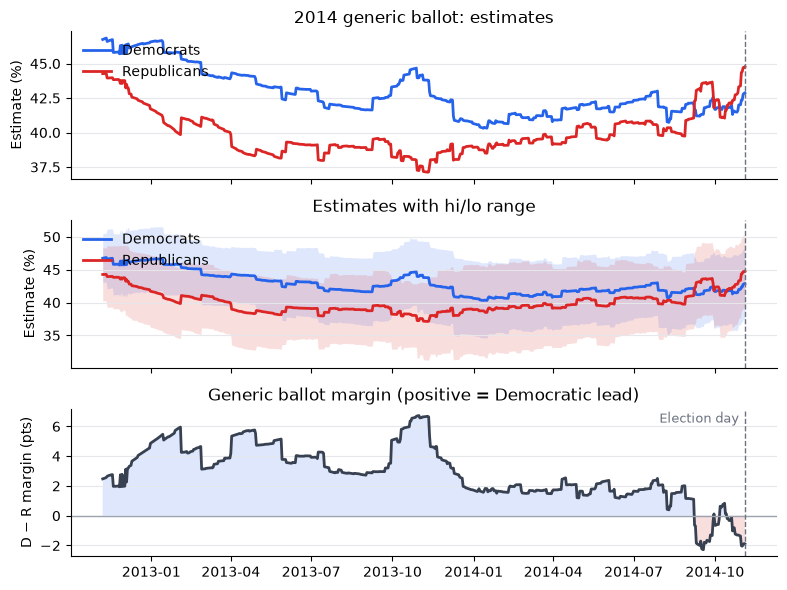

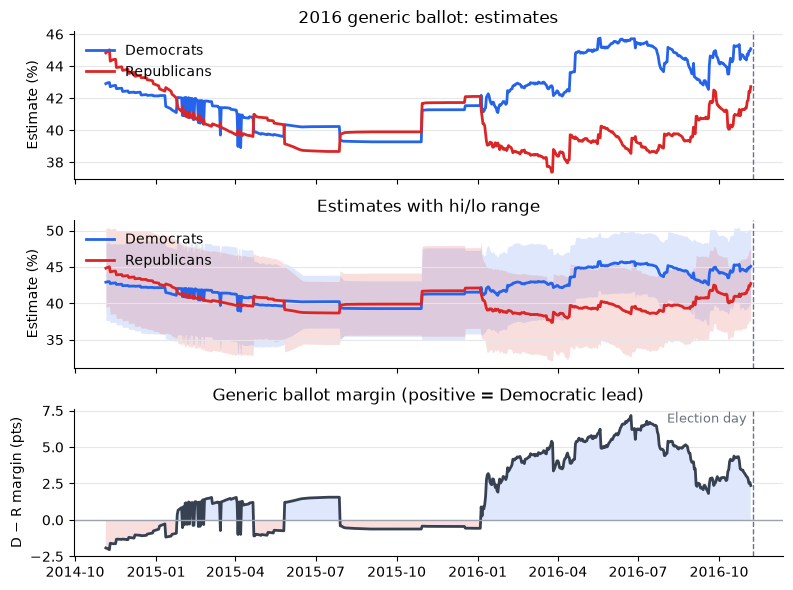

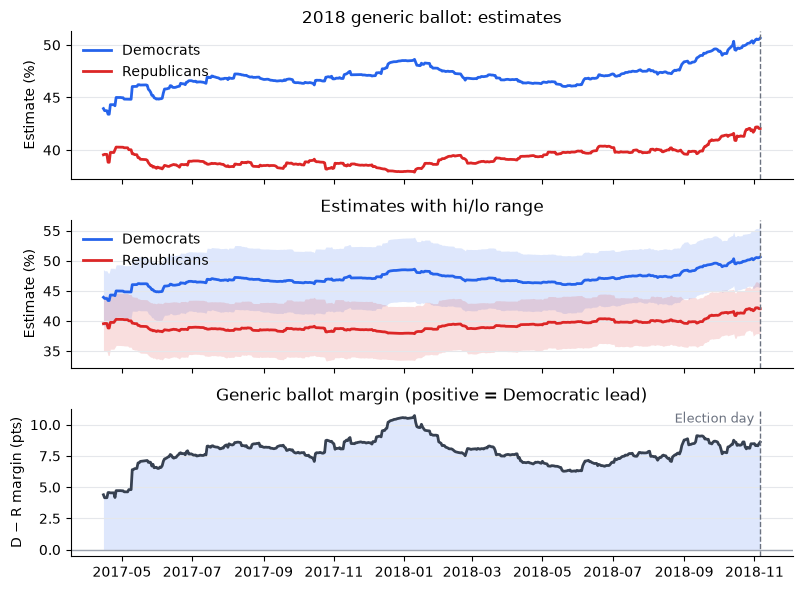

In [10]:
ELECTION_YEARS = [2014, 2016, 2018]


def plot_elections(df: pd.DataFrame, election_years: list[int]) -> list[plt.Figure]:
    """Plot each requested cycle with plot_election, after checking every year exists in the data."""
    available = set(df["election"].unique().tolist())
    missing = sorted(set(election_years) - available)
    if missing:
        raise ValueError(f"No data for {missing}; available: {sorted(available)}")
    return [plot_election(df, year) for year in election_years]


plot_elections(generic_ballot, ELECTION_YEARS);

In [ ]:
def ballot_at_cutoffs(df: pd.DataFrame, election_dates: pd.DataFrame) -> pd.DataFrame:
    """For each election, take the last generic-ballot row of its cycle on or before the day before the election."""
    cutoffs = election_dates[["election", "day_before"]].rename(columns={"day_before": "cutoff_date"})
    cutoffs = cutoffs.astype({"cutoff_date": df["date"].dtype}).sort_values("cutoff_date")
    matched = pd.merge_asof(
        cutoffs,
        df.sort_values("date"),
        left_on="cutoff_date",
        right_on="date",
        by="election",
        direction="backward",
    )
    # elections outside the data's coverage (pre-1996, future cycles) have no row to match
    matched = matched.dropna(subset=["date"]).astype({"election": int})
    columns = [c for c in df.columns if c != "election"]
    return matched[["election", "cutoff_date", *columns]].reset_index(drop=True)


generic_ballot_cutoffs = ballot_at_cutoffs(generic_ballot, election_dates)
generic_ballot_cutoffs.to_parquet(REFERENCE_DIR / "generic_ballot.parquet", index=False)
generic_ballot_cutoffs.to_csv(REFERENCE_DIR / "generic_ballot.csv", index=False)
generic_ballot_cutoffs

In [ ]:
import numpy as np


def validate_generic_ballot(df: pd.DataFrame, cutoffs: pd.DataFrame, window: int = TREND_WINDOW_DAYS) -> None:
    """Independently recompute every derived column by calendar date and raise if anything disagrees.

    Deliberately avoids the row-based shortcuts used in add_trend_features: windows are found by date,
    and the EWMA is rebuilt from its recursive definition, so a bug in one path is caught by the other.
    """
    failures = []

    def check(ok, message: str) -> None:
        if not ok:
            failures.append(message)

    two_party = df["dem_estimate"] + df["gop_estimate"]
    check(np.allclose(df["margin_raw"], df["dem_estimate"] - df["gop_estimate"]), "margin_raw != D - R")
    check(np.allclose(df["margin_2p_norm"], 100 * df["margin_raw"] / two_party), "margin_2p_norm != 100(D-R)/(D+R)")
    check(np.allclose(df["und_estimate"], 100 - two_party), "und_estimate != 100 - D - R")
    for party in ("dem", "gop"):
        est, hi, lo = df[f"{party}_estimate"], df[f"{party}_hi"], df[f"{party}_lo"]
        check(((lo <= est) & (est <= hi)).all(), f"{party}_estimate outside [{party}_lo, {party}_hi]")
    trend_cols = [c for c in df.columns if f"{window}d" in c]
    check(df.drop(columns=trend_cols).notna().all().all(), "missing values outside trend columns")

    alpha = 2 / (window + 1)
    by_date = df.set_index("date")
    for election, cycle in df.groupby("election"):
        cycle = cycle.sort_values("date")
        ewma_state = {col: (0.0, 0.0) for col in TREND_MARGINS.values()}
        for _, row in cycle.iterrows():
            # EWMA (adjust=True) as a running weighted average that starts fresh each cycle
            ewma = {}
            for col in TREND_MARGINS.values():
                num, den = ewma_state[col]
                num, den = row[col] + (1 - alpha) * num, 1 + (1 - alpha) * den
                ewma_state[col], ewma[col] = (num, den), num / den

            lag_date = row["date"] - pd.Timedelta(days=window)
            if lag_date not in by_date.index or by_date.loc[lag_date, "election"] != election:
                check(row[trend_cols].isna().all(), f"{row['date'].date()}: trend value without {window}d in-cycle history")
                continue

            win = by_date.loc[row["date"] - pd.Timedelta(days=window - 1) : row["date"]]
            check(len(win) == window and (win["election"] == election).all(), f"{row['date'].date()}: window leaves cycle")
            for suffix, col in TREND_MARGINS.items():
                check(np.isclose(row[f"margin_{window}d_mean_{suffix}"], win[col].mean()), f"{row['date'].date()}: mean {suffix}")
                check(np.isclose(row[f"margin_{window}d_ewma_{suffix}"], ewma[col]), f"{row['date'].date()}: ewma {suffix}")
                momentum = row[col] - by_date.loc[lag_date, col]
                check(np.isclose(row[f"momentum_{window}d_{suffix}"], momentum), f"{row['date'].date()}: momentum {suffix}")

    matched = cutoffs.drop(columns="cutoff_date").merge(df, how="left", indicator=True)
    check(matched["_merge"].eq("both").all(), "cutoff rows differ from the full table")
    check((cutoffs["date"] <= cutoffs["cutoff_date"]).all(), "cutoff row dated after its cutoff")
    check((cutoffs["cutoff_date"].dt.year == cutoffs["election"]).all(), "cutoff row from the wrong cycle")

    if failures:
        raise AssertionError(f"{len(failures)} check(s) failed, first 10:\n" + "\n".join(failures[:10]))
    n_valid = df[f"momentum_{window}d_raw"].notna().sum()
    print(f"All checks passed: {len(df)} rows ({n_valid} with {window}d trends), {len(cutoffs)} cutoff rows")


validate_generic_ballot(generic_ballot, generic_ballot_cutoffs)